Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)
Mounted at /content/drive
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to patinhos-1 in yolov8:: 100%|██████████| 964/964 [00:00<00:00, 10617.07it/s]


Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/patinhos-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=modelo_patinho-2, nbs=64, nms=None, opset=None, optimize=Fa

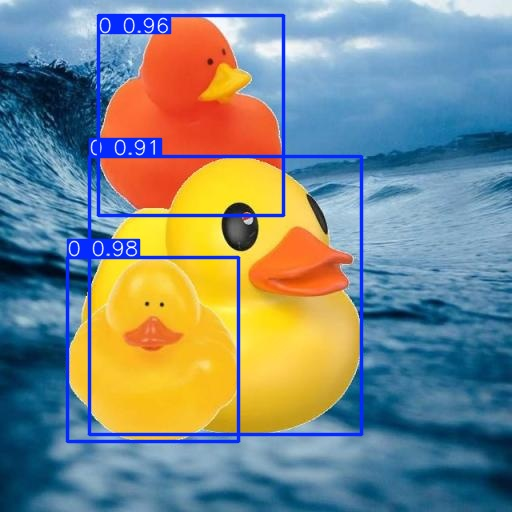

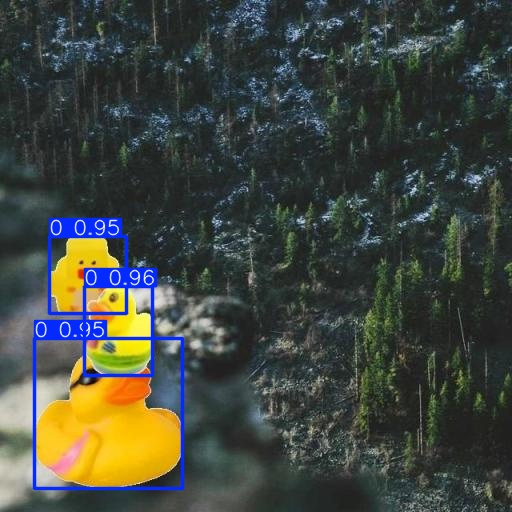

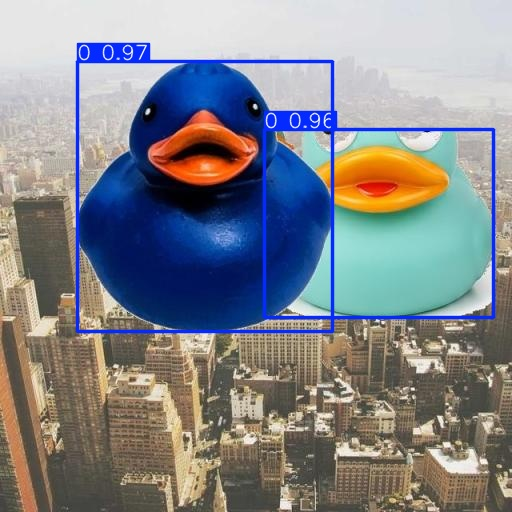

In [1]:
import os
import glob
from IPython.display import Image, display

!pip install -q ultralytics roboflow

import ultralytics
ultralytics.checks()

from google.colab import drive
drive.mount('/content/drive')

from roboflow import Roboflow

API_KEY = "NI53fUGLdi9XkmW26g8o"

rf = Roboflow(api_key=API_KEY)

project = rf.workspace("carolina-viana-de-souza").project("patinhos")
dataset = project.version(1).download("yolov8")

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
     data=f"{dataset.location}/data.yaml",
     epochs=50,
     batch=16,
     imgsz=640,
     plots=True,
     project="/content/drive/MyDrive/yolo_treinamentos",
     name="modelo_patinho"
 )

model_trained = YOLO("/content/drive/MyDrive/yolo_treinamentos/modelo_patinho/weights/best.pt")

test_images_path = f"{dataset.location}/test/images"
results_predict = model_trained.predict(source=test_images_path, save=True, conf=0.25)

for image_path in glob.glob('/content/runs/detect/predict/*.jpg')[:3]:
     display(Image(filename=image_path, width=600))